# 제6교시. 전체 범위·슬라이딩 윈도우 어텐션을 섞는 실제 모델 설계


## 이번 교시의 목표

- gpt-oss-20b의 공식 설정으로 전체 범위 어텐션과 슬라이딩 윈도우 어텐션을 한 층씩 번갈아 쓰는 구조를 살펴봅니다. 모델 가중치는 실행하지 않습니다.
- 슬라이딩 윈도우 층에서 현재 토큰을 포함해 최대 128개 위치를 참고하지만, 다음 토큰을 위해 과거 K·V는 최대 127개 위치만 남기는 이유를 설명합니다.
- 입력 길이에 따른 KV 캐시 저장량을 계산하고, 24층 모두 전체 범위 어텐션이라고 가정한 경우와 비교합니다.

## 이번 교시 핵심 용어

- **전체 범위 인과적 셀프 어텐션 (full causal self-attention)**: 현재 위치와 그 이전의 모든 위치를 직접 참고하며 미래 위치는 읽지 않습니다. 이후에는 **전체 범위 어텐션**으로 줄여 씁니다.
- **슬라이딩 윈도우 인과적 셀프 어텐션 (sliding-window causal self-attention)**: 현재를 포함한 최근 윈도우 안의 위치만 직접 참고하며 미래 위치는 읽지 않습니다. 이후에는 **슬라이딩 윈도우 어텐션**으로 줄여 씁니다.
- **어텐션 수용 범위(receptive field)**: 한 표현에 영향을 줄 수 있는 위치 범위이며 직접 접근과 여러 층을 거친 간접 전달을 구별합니다.
- **키·값 캐시(key–value cache, KV cache)**: 재사용할 K·V를 보관하는 구조로 층의 어텐션 종류에 따라 보관 규칙이 달라질 수 있습니다.

## 실습 준비

제1교시 프로젝트 커널로 위에서부터 실행합니다. 설정 원본이 Notebook에 들어 있어 인터넷·새 패키지·새 가중치가 필요 없습니다. 이 셀은 호스트의 설정 처리이며 CUDA 연산이나 20B 가중치 실행은 하지 않습니다.

**열기와 실행:** VS Code에서 이 `.ipynb`를 열고 오른쪽 위 커널 선택에서 제1교시에 준비한 프로젝트 가상환경의 Python을 선택합니다. 그림과 필요한 설정은 노트북에 내장되어 있으므로 별도 가이드북이나 그림 파일을 열 필요가 없습니다. 제1교시에서 준비한 `transformers==5.23.0`과 그 의존 패키지가 필요합니다. 가중치를 다운로드하거나 학습·추론하지 않으며 설치된 라이브러리의 소스와 설정만 읽습니다.

**진행과 문제 확인:** 위에서부터 개념·그림·코드 설명을 확인하고 해당 코드 셀을 실행한 뒤 바로 아래 출력 설명과 대조합니다. 앞 셀의 변수와 함수를 다음 셀이 사용하므로 중간부터 실행하지 않습니다. 오류가 나면 이후 셀을 진행하지 말고 오류 전문과 마지막 성공 셀을 보존하세요. `NameError`는 앞 셀 실행 여부, `ModuleNotFoundError`는 선택한 커널과 제1교시 준비 상태, `AssertionError`는 바로 위 검사 조건과 출력값을 확인합니다. 버전이나 커널을 바꾼 뒤에는 처음부터 다시 실행하고 실행 출력이 포함된 노트북을 저장합니다. PASS는 각 셀에 적힌 검사 범위만을 뜻합니다.

이번에는 **gpt-oss-20b의 공식 설정과 실제 설치된 구현**을 읽습니다. 수업용 축소 모델을 만들지 않습니다. 대신 대형 모델의 가중치를 다운로드하거나 실행하지 않고, 실제 24층의 순서·마스크 범위·캐시 저장 규칙을 추적합니다. 이 교시의 PASS는 **설정·소스 분석 코드**가 통과했다는 의미이며 GPT-OSS GPU 추론 성공이 아닙니다.

여기서 살펴보는 **gpt-oss-20b**는 OpenAI가 [2025년 8월 5일](https://openai.com/index/introducing-gpt-oss/)에 gpt-oss-120b와 함께 공개했습니다. 이번 교시는 두 크기 중 20b의 설정과 구현만 읽습니다.


## 1. 무엇을 섞는가?

**하이브리드(hybrid)란 무엇일까요?** 여기서는 앞선 토큰의 정보를 처리하는 방식이 서로 다른 층을 한 모델에 함께 두는 설계를 말합니다. 무엇을 섞을지와 어느 층에 얼마나 배치할지는 모델마다 다릅니다. 꼭 한 층씩 번갈아 쌓아야 하는 것은 아닙니다.

**gpt-oss-20b는 ‘어디까지 직접 보느냐’가 다른 두 어텐션을 섞습니다.** 전체 범위 어텐션은 현재 위치와 그 이전의 모든 위치를, 슬라이딩 윈도우 어텐션은 현재 위치를 포함한 최근 구간만 직접 참고합니다. 둘 다 미래 토큰은 보지 않습니다. gpt-oss-20b의 24개 층은 슬라이딩 윈도우 층과 전체 범위 층을 하나씩 번갈아 배치합니다. 가까운 범위만 참고하는 층을 두면서도, 먼 위치를 직접 참고할 수 있는 층을 남기는 설계입니다.

이후 층 종류를 설명할 때는 **전체 범위 층**, **슬라이딩 윈도우 층**이라고 부릅니다. 다른 모델의 Mamba·Gated DeltaNet 같은 별도 메커니즘까지 이 두 방식으로 부르는 것은 아닙니다.

### 참고: 모델마다 무엇을 다르게 섞을까요?

| 모델 | 무엇을 섞나요? | 어떻게 배치하나요? |
|---|---|---|
| gpt-oss-20b | 슬라이딩 윈도우 어텐션 + 전체 범위 어텐션 | 최근 최대 128개 위치를 보는 층 **1개**와 전체 범위 층 **1개**를 번갈아 배치합니다. [OpenAI 모델 카드 §2.2](https://arxiv.org/html/2508.10925#S2.SS2) |
| Gemma 3 | 슬라이딩 윈도우 어텐션 + 전체 범위 어텐션 | 최근 최대 1,024개 위치를 보는 층 **5개**에 전체 범위 층 **1개**를 배치합니다. [Gemma 3 공식 설명: 5 대 1 어텐션](https://gemma.ai/tutorials/gemma-explained/gemma-3/#5-to-1-interleaved-attention) |
| Jamba | 어텐션 + Mamba 상태공간 모델(state space model, SSM) | 논문에 공개된 구성은 8개 층마다 어텐션 **1개**, Mamba **7개**입니다. [AI21 논문 §3.1](https://arxiv.org/html/2403.19887#S3.SS1) |
| Qwen3-Next-80B-A3B | Gated DeltaNet(선형 어텐션 계열) + Gated Attention(게이트를 더한 전체 범위 어텐션) | Gated DeltaNet **3개** 뒤에 Gated Attention **1개**를 두는 패턴을 반복합니다. [Qwen 공식 모델 카드](https://huggingface.co/Qwen/Qwen3-Next-80B-A3B-Instruct#model-overview) |

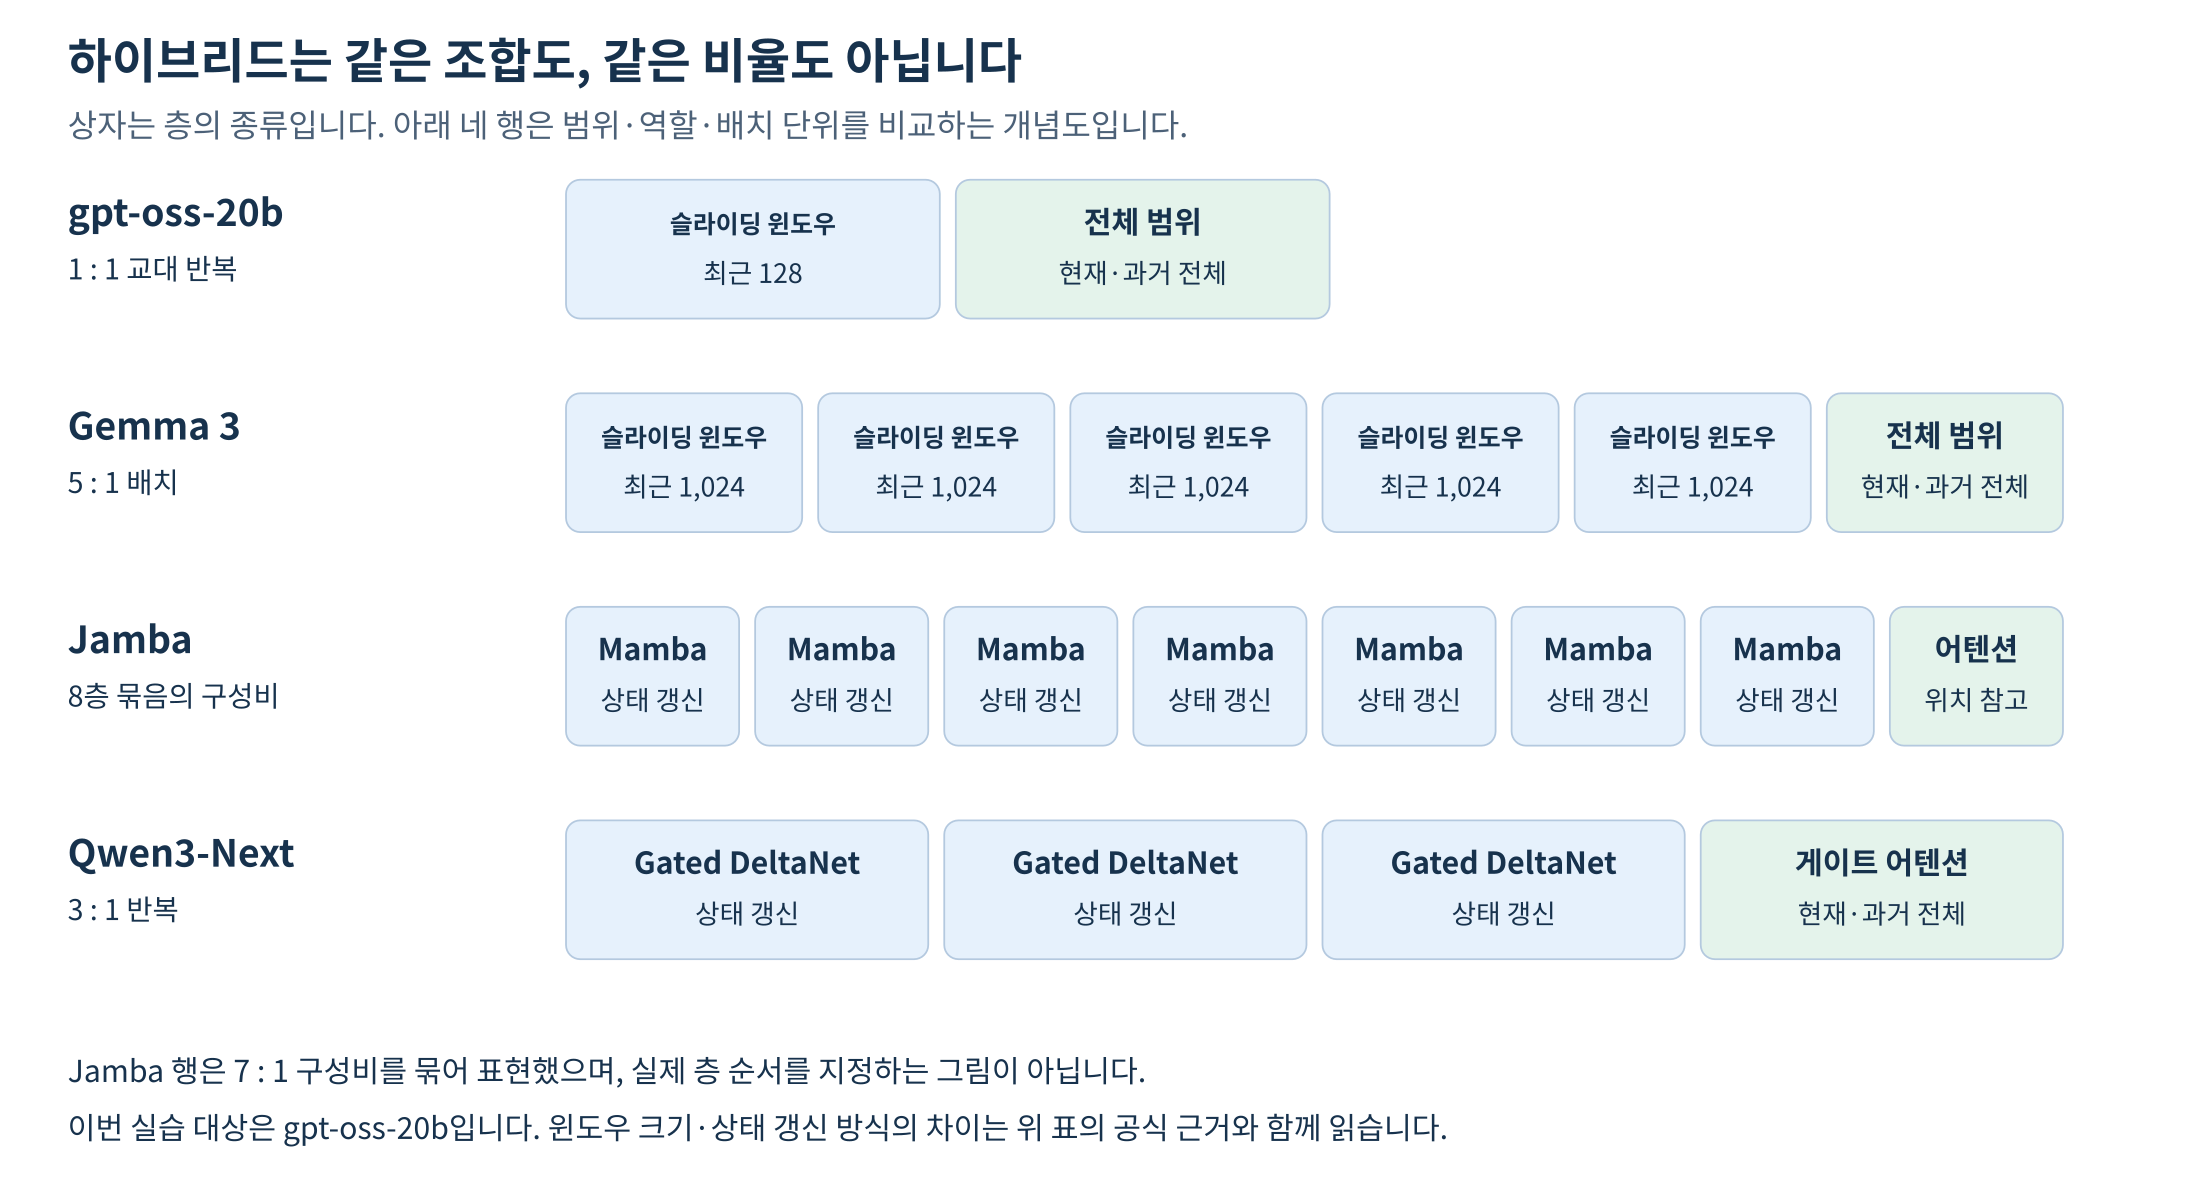

**그림 설명:** 어떤 종류를 몇 개씩 섞는지 비교합니다. Jamba는 구성비만 표시하며, 위치 번호나 실제 실행 결과가 아닙니다.

**표에서 무엇을 비교하면 될까요?** gpt-oss-20b와 Gemma 3는 같은 두 어텐션을 쓰되 윈도우 크기와 층 비율을 달리합니다. 반면 Jamba의 Mamba와 Qwen3-Next의 Gated DeltaNet은 과거 위치를 하나씩 다시 조회하는 대신, 앞서 처리한 정보를 내부 상태에 반영해 전달합니다. 두 방식의 상태 갱신 규칙은 서로 다릅니다. 이렇게 하이브리드는 **어텐션의 참고 범위**를 달리할 수도 있고, **과거 정보를 가져오는 방식 자체**를 달리할 수도 있습니다.

이번 실습에서는 네 모델 중 **gpt-oss-20b의 설정과 구현**만 살펴봅니다.


### 개념 연결: 가까운 문맥, 먼 문맥, 재사용할 계산

긴 글의 첫머리에 **“반려견의 이름은 보리입니다.”**라고 적혀 있고, 여러 문단 뒤에 **“반려견의 이름은”**이라는 표현이 다시 등장한다고 생각해 보세요. 바로 뒤를 이어 쓰려면 가까운 문장의 표현도 필요하지만, 앞부분에 나온 이름도 필요할 수 있습니다. 이 문장은 이해를 위한 예시이며, 이번 교시에서 실제로 생성하거나 정답률을 검사하는 입력은 아닙니다.

슬라이딩 윈도우 어텐션은 **현재를 포함한 최근 윈도우 안의 위치**를 직접 참고합니다. 바로 앞의 “반려견의 이름은”은 읽을 수 있어도, 처음 나온 “보리”가 윈도우 밖에 있으면 그 위치의 K·V를 해당 층에서 직접 조회하지 못합니다. 전체 범위 어텐션은 현재까지의 모든 위치를 직접 참고할 수 있으므로, 앞부분 이름에도 접근할 경로가 있습니다. 두 방식 모두 미래 위치는 보지 않습니다. 또한 읽을 수 있다는 사실이 그 이름을 반드시 정확히 답한다는 보장은 아닙니다.

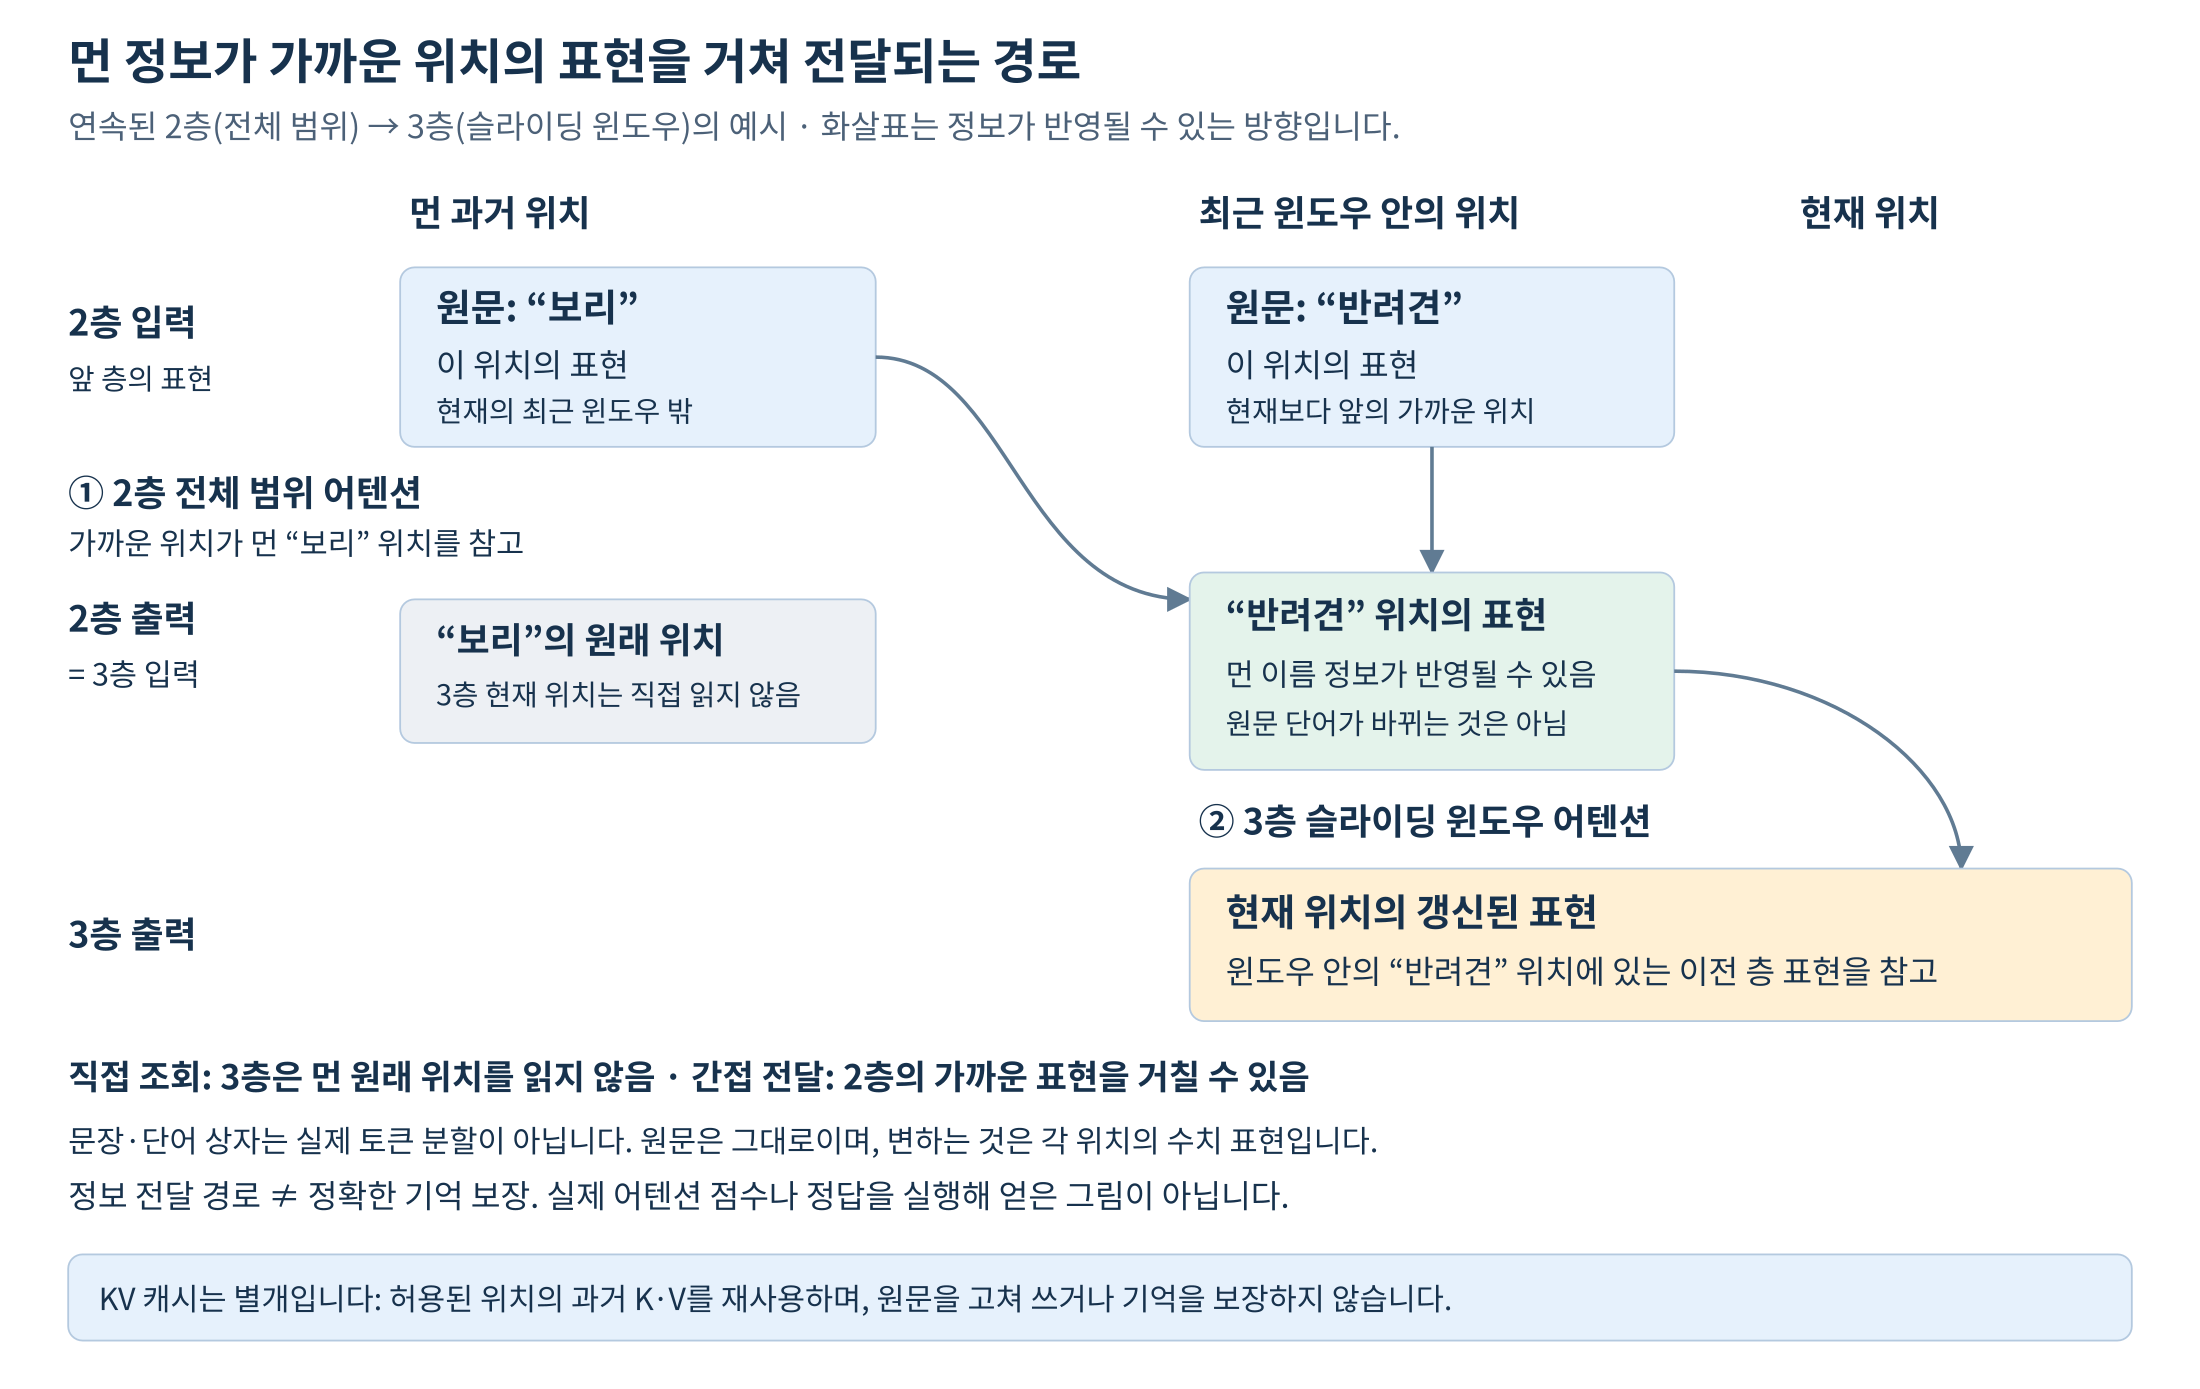

**그림 설명:** 2층 출력은 바로 다음 3층의 입력입니다. 먼 “보리”의 원래 위치는 3층 현재 위치의 윈도우 밖이므로 직접 읽지 않습니다. 화살표는 정보가 반영될 수 있는 방향이며 기억 보장을 뜻하지 않습니다. 문장·단어 상자는 실제 토큰 분할이 아니며, 원문 글자는 그대로입니다. 실제 윈도우 크기는 128입니다.

**직접 읽기와 간접 전달을 두 층으로 따라가 보세요.** 실제 교대 순서에 맞추어 **2층은 전체 범위 어텐션, 바로 다음 3층은 슬라이딩 윈도우 어텐션**이라고 하겠습니다. 먼 과거의 “보리”는 3층 현재 위치의 윈도우 밖에 있고, 가까운 “반려견”은 현재보다 앞이면서 윈도우 안에 있다고 가정합니다.

1. **2층 전체 범위 어텐션:** 가까운 “반려견” 위치가 앞부분의 “보리” 위치를 참고합니다. 이때 가까운 위치의 출력 표현에 이름 정보가 반영될 수 있습니다. 이 출력은 다음 3층의 입력 표현이 됩니다.
2. **3층 슬라이딩 윈도우 어텐션:** 현재 위치는 윈도우 안에 있는 “반려견” 위치의 **이전 층 출력 표현**을 참고합니다. 그 표현을 통해 먼 이름 정보가 간접적으로 영향을 줄 수 있습니다. 하지만 윈도우 밖의 “보리” 원래 위치를 3층에서 직접 읽은 것은 아닙니다.

**원문 단어가 바뀌는 것은 아닙니다.** “반려견”이라는 글자가 “보리”로 수정되는 것이 아니라, 그 위치를 나타내는 수치 벡터가 앞 층에서 갱신됩니다. 화살표는 정보가 반영될 수 있는 방향을 나타냅니다. 이런 경로가 존재하더라도 이름 정보가 정확히 보존되거나 다음 답변이 반드시 “보리”가 된다고 보장하지는 않습니다.

**KV 캐시는 이와 별개로 ‘같은 계산을 다시 할 것인가’에 관한 장치입니다.** 어텐션 종류는 읽기를 허용하는 위치 범위를 정하고, 캐시는 그 읽기에 사용할 과거 K·V를 재사용하게 해 줍니다. 캐시는 원문 문장을 보관한 검색 문서도, 모델이 학습한 지식 전체도 아닙니다. 허용 범위가 다르면 다음 호출을 위해 남겨 둘 K·V의 범위도 달라질 수 있습니다.

이후에는 예시 문장의 정답을 생성하는 대신, 실제 설정에서 두 층이 어떻게 배치되는지, 각 층이 어느 위치에 직접 접근할 수 있는지, 캐시 구현이 다음 호출을 위해 무엇을 남기는지를 순서대로 확인합니다. 마지막으로 그 보관 규칙을 바이트 수로 바꾸어 비교합니다.


### 설정을 읽는 것과 모델을 불러오는 것은 다릅니다
입력은 특정 **revision(저장소의 고정 버전)**에서 가져온 gpt-oss-20b의 `config.json` 원본입니다. `Base64`는 원본 바이트를 노트북 안에 담기 위한 표현 방식이며 암호화나 모델 압축이 아닙니다. 이를 복원하고 `SHA256` 지문을 비교하여 수업에서 정한 원본과 같은지 검사합니다.

`GptOssConfig`는 층 수·윈도우 크기 같은 설계 정보를 담는 객체입니다. **학습 가중치를 로드하거나 20B 모델을 생성하는 코드가 아닙니다.** 이 설정 처리 자체에는 CUDA 연산이 필요하지 않습니다. 출력의 `24 / 128 / 8 / 64`는 차례로 블록 수, 슬라이딩 윈도우 크기, K·V 헤드 수, 헤드당 차원입니다. 블록은 어텐션과 FFN 등을 묶은 반복 단위입니다.

`[PASS] 공식 설정 원본과 해시 확인`은 원본 및 주요 설정값 검사가 통과했다는 뜻이며 생성 품질을 검증한 것은 아닙니다.

### 코드 설명: 원본 바이트 → 사전 → 설정 객체

공식 설정을 복원하고 원본 지문과 주요 구조값을 확인합니다. 문자열·바이트·사전·설정 객체로 표현을 바꾸는 과정이며, 모델 가중치를 로드하는 단계가 아닙니다.

SHA-256은 받은 설정 파일이 같은 원본인지 확인하는 지문입니다. 그다음 JSON 사전의 항목을 설정 객체로 옮겨 층 수와 윈도우 크기를 확인합니다. 여기서 만든 것은 모델이 아니라 설정을 담은 객체입니다.


In [1]:
import json, hashlib, base64, platform, sys, ast
from pathlib import Path
from collections import Counter
import transformers
from transformers import GptOssConfig, DynamicCache
# 운영체제 조건만 검사하며 CUDA 사용이나 GPU 추론 여부를 검사하지 않습니다.
assert platform.system() == "Windows", "Windows 11 교육 환경을 사용하세요."
print("Python:", sys.version.split()[0], "transformers:", transformers.__version__)
# 공식 고정 revision config.json의 원본 바이트입니다. 수정할 필요가 없습니다.
CONFIG_BASE64 = 'ewogICJhcmNoaXRlY3R1cmVzIjogWwogICAgIkdwdE9zc0ZvckNhdXNhbExNIgogIF0sCiAgImF0dGVudGlvbl9iaWFzIjogdHJ1ZSwKICAiYXR0ZW50aW9uX2Ryb3BvdXQiOiAwLjAsCiAgImVvc190b2tlbl9pZCI6IDIwMDAwMiwKICAiZXhwZXJ0c19wZXJfdG9rZW4iOiA0LAogICJoZWFkX2RpbSI6IDY0LAogICJoaWRkZW5fYWN0IjogInNpbHUiLAogICJoaWRkZW5fc2l6ZSI6IDI4ODAsCiAgImluaXRpYWxfY29udGV4dF9sZW5ndGgiOiA0MDk2LAogICJpbml0aWFsaXplcl9yYW5nZSI6IDAuMDIsCiAgImludGVybWVkaWF0ZV9zaXplIjogMjg4MCwKICAibGF5ZXJfdHlwZXMiOiBbCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgImZ1bGxfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAiZnVsbF9hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJmdWxsX2F0dGVudGlvbiIsCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgImZ1bGxfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAiZnVsbF9hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJmdWxsX2F0dGVudGlvbiIsCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgImZ1bGxfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAiZnVsbF9hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJmdWxsX2F0dGVudGlvbiIsCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgImZ1bGxfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAiZnVsbF9hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJmdWxsX2F0dGVudGlvbiIKICBdLAogICJtYXhfcG9zaXRpb25fZW1iZWRkaW5ncyI6IDEzMTA3MiwKICAibW9kZWxfdHlwZSI6ICJncHRfb3NzIiwKICAibnVtX2F0dGVudGlvbl9oZWFkcyI6IDY0LAogICJudW1fZXhwZXJ0c19wZXJfdG9rIjogNCwKICAibnVtX2hpZGRlbl9sYXllcnMiOiAyNCwKICAibnVtX2tleV92YWx1ZV9oZWFkcyI6IDgsCiAgIm51bV9sb2NhbF9leHBlcnRzIjogMzIsCiAgIm91dHB1dF9yb3V0ZXJfbG9naXRzIjogZmFsc2UsCiAgInBhZF90b2tlbl9pZCI6IDE5OTk5OSwKICAicXVhbnRpemF0aW9uX2NvbmZpZyI6IHsKICAgICJtb2R1bGVzX3RvX25vdF9jb252ZXJ0IjogWwogICAgICAibW9kZWwubGF5ZXJzLiouc2VsZl9hdHRuIiwKICAgICAgIm1vZGVsLmxheWVycy4qLm1scC5yb3V0ZXIiLAogICAgICAibW9kZWwuZW1iZWRfdG9rZW5zIiwKICAgICAgImxtX2hlYWQiCiAgICBdLAogICAgInF1YW50X21ldGhvZCI6ICJteGZwNCIKICB9LAogICJybXNfbm9ybV9lcHMiOiAxZS0wNSwKICAicm9wZV9zY2FsaW5nIjogewogICAgImJldGFfZmFzdCI6IDMyLjAsCiAgICAiYmV0YV9zbG93IjogMS4wLAogICAgImZhY3RvciI6IDMyLjAsCiAgICAib3JpZ2luYWxfbWF4X3Bvc2l0aW9uX2VtYmVkZGluZ3MiOiA0MDk2LAogICAgInJvcGVfdHlwZSI6ICJ5YXJuIiwKICAgICJ0cnVuY2F0ZSI6IGZhbHNlCiAgfSwKICAicm9wZV90aGV0YSI6IDE1MDAwMCwKICAicm91dGVyX2F1eF9sb3NzX2NvZWYiOiAwLjksCiAgInNsaWRpbmdfd2luZG93IjogMTI4LAogICJzd2lnbHVfbGltaXQiOiA3LjAsCiAgInRpZV93b3JkX2VtYmVkZGluZ3MiOiBmYWxzZSwKICAidHJhbnNmb3JtZXJzX3ZlcnNpb24iOiAiNC41NS4wLmRldjAiLAogICJ1c2VfY2FjaGUiOiB0cnVlLAogICJ2b2NhYl9zaXplIjogMjAxMDg4Cn0K'
# 내장한 공식 설정 바이트를 복원할 뿐 모델 가중치를 읽지 않습니다.
# Base64 문자열 → 원본 바이트이며, 다음 해시 검사는 내용 동일성을 확인합니다.
raw = base64.b64decode(CONFIG_BASE64)
assert hashlib.sha256(raw).hexdigest() == '3a2a26ded679375b7928ddeca59764df7cea83220c1961035f6d6e232659e9ce'
# JSON 사전으로 읽은 뒤 **로 이름 붙은 인자를 전달해 설정 객체를 만듭니다.
# raw는 JSON 파일의 바이트이고 config_data는 필드명→값 사전입니다. 해시 일치와 모델 성능은 별개입니다.
config_data = json.loads(raw)
# **는 사전의 키를 생성자의 매개변수 이름으로 전달합니다. 설정 객체에는 학습된 행렬이 없습니다.
config = GptOssConfig(**config_data)
print("Model:", config_data["architectures"])
print("Source revision: 6cee5e81ee83917806bbde320786a8fb61efebee")
print("Config SHA256:", hashlib.sha256(raw).hexdigest())
print("Scope: configuration/source inspection only; no checkpoint weights or inference")
# 층 수·윈도우 크기·KV 헤드·헤드 차원을 각각 검사하며 입력 텐서 shape는 아닙니다.
assert config.num_hidden_layers == 24 and config.sliding_window == 128
assert config.num_key_value_heads == 8 and config.head_dim == 64
print("layers / window / KV heads / head dim:", 24, 128, 8, 64)
print("[PASS] 공식 설정 원본과 해시 확인")

%USERPROFILE%\AI-Engineering\python31210-signed-qa-20261117\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.10 transformers: 5.23.0
Model: ['GptOssForCausalLM']
Source revision: 6cee5e81ee83917806bbde320786a8fb61efebee
Config SHA256: 3a2a26ded679375b7928ddeca59764df7cea83220c1961035f6d6e232659e9ce
Scope: configuration/source inspection only; no checkpoint weights or inference
layers / window / KV heads / head dim: 24 128 8 64
[PASS] 공식 설정 원본과 해시 확인


### 출력 설명: 설계값 네 개는 서로 다른 크기입니다

- `24 / 128 / 8 / 64`는 **블록 24개 / 슬라이딩 윈도우 128위치 / KV 헤드 8개 / 헤드당 64성분** 순서입니다. 128을 전체 모델의 최대 문맥 길이로 읽거나, 8을 Query 헤드 수로 읽으면 안 됩니다.
- `GptOssForCausalLM`은 설정에 적힌 모델 클래스 이름입니다. 클래스 이름이 표시되었다고 그 모델의 가중치를 생성·로드한 것은 아닙니다. `Scope` 줄은 이번 작업이 설정·소스 확인임을 명시합니다.
- `Source revision`은 설정을 가져온 고정 버전, `Config SHA256`은 복원한 원본 바이트의 내용 지문입니다. 끝의 PASS는 지문과 주요 구조값 검사를 통과했다는 뜻입니다. 긴 지문을 외울 필요는 없으며, 자료의 버전과 내용이 고정되어 있다는 역할을 이해하면 됩니다.

이 결과로 다음 셀에서 24개 블록의 배치를 읽을 준비가 되었습니다. 아직 입력 문장, 어텐션 가중치, 생성 결과는 없습니다.

환경 표시는 **Python 3.12.10 / Transformers 5.23.0**입니다. 이 버전은 뒤에서 읽는 설치 소스의 기준이며, 모델 정확도나 속도 수치가 아닙니다.

## 2. 24개 층의 배치 순서 설명

**어떤 순서로 두 종류의 층을 배치했을까요?** gpt-oss-20b의 공식 설정에는 `layer_types`라는 목록이 있습니다. 각 항목은 해당 블록에서 사용할 어텐션 종류를 나타냅니다. 첫 항목은 `sliding_attention`, 다음 항목은 `full_attention`이며 이 순서가 24개 층에 걸쳐 반복됩니다. 블록 전체가 어텐션만으로 이루어졌다는 뜻은 아닙니다. 여기서는 블록 안의 어텐션 종류만 확인합니다.

**목록의 인덱스와 층 번호를 구별하세요.** Python 목록은 첫 항목을 인덱스 0으로 부르지만, 설명에서는 첫 블록을 1층으로 부릅니다. 따라서 `index 0 / layer 1`은 같은 층입니다. 인덱스 0·2·4처럼 짝수인 항목은 슬라이딩 윈도우 어텐션이며, 사람이 세는 층 번호로는 1·3·5층처럼 홀수 층입니다. 두 번호가 다르게 보여도 모델 구조가 달라진 것은 아닙니다.

**왜 개수와 순서를 모두 확인하나요?** 슬라이딩 윈도우 12개와 전체 범위 12개가 있다는 사실만으로 ‘번갈아 배치했다’고 판단할 수는 없습니다. 슬라이딩 윈도우 층을 앞쪽 12개에 몰아 놓아도 개수는 같기 때문입니다. 앞 층에서 만들어진 표현을 뒤 층이 처리하므로 배치 순서도 구조의 일부입니다.

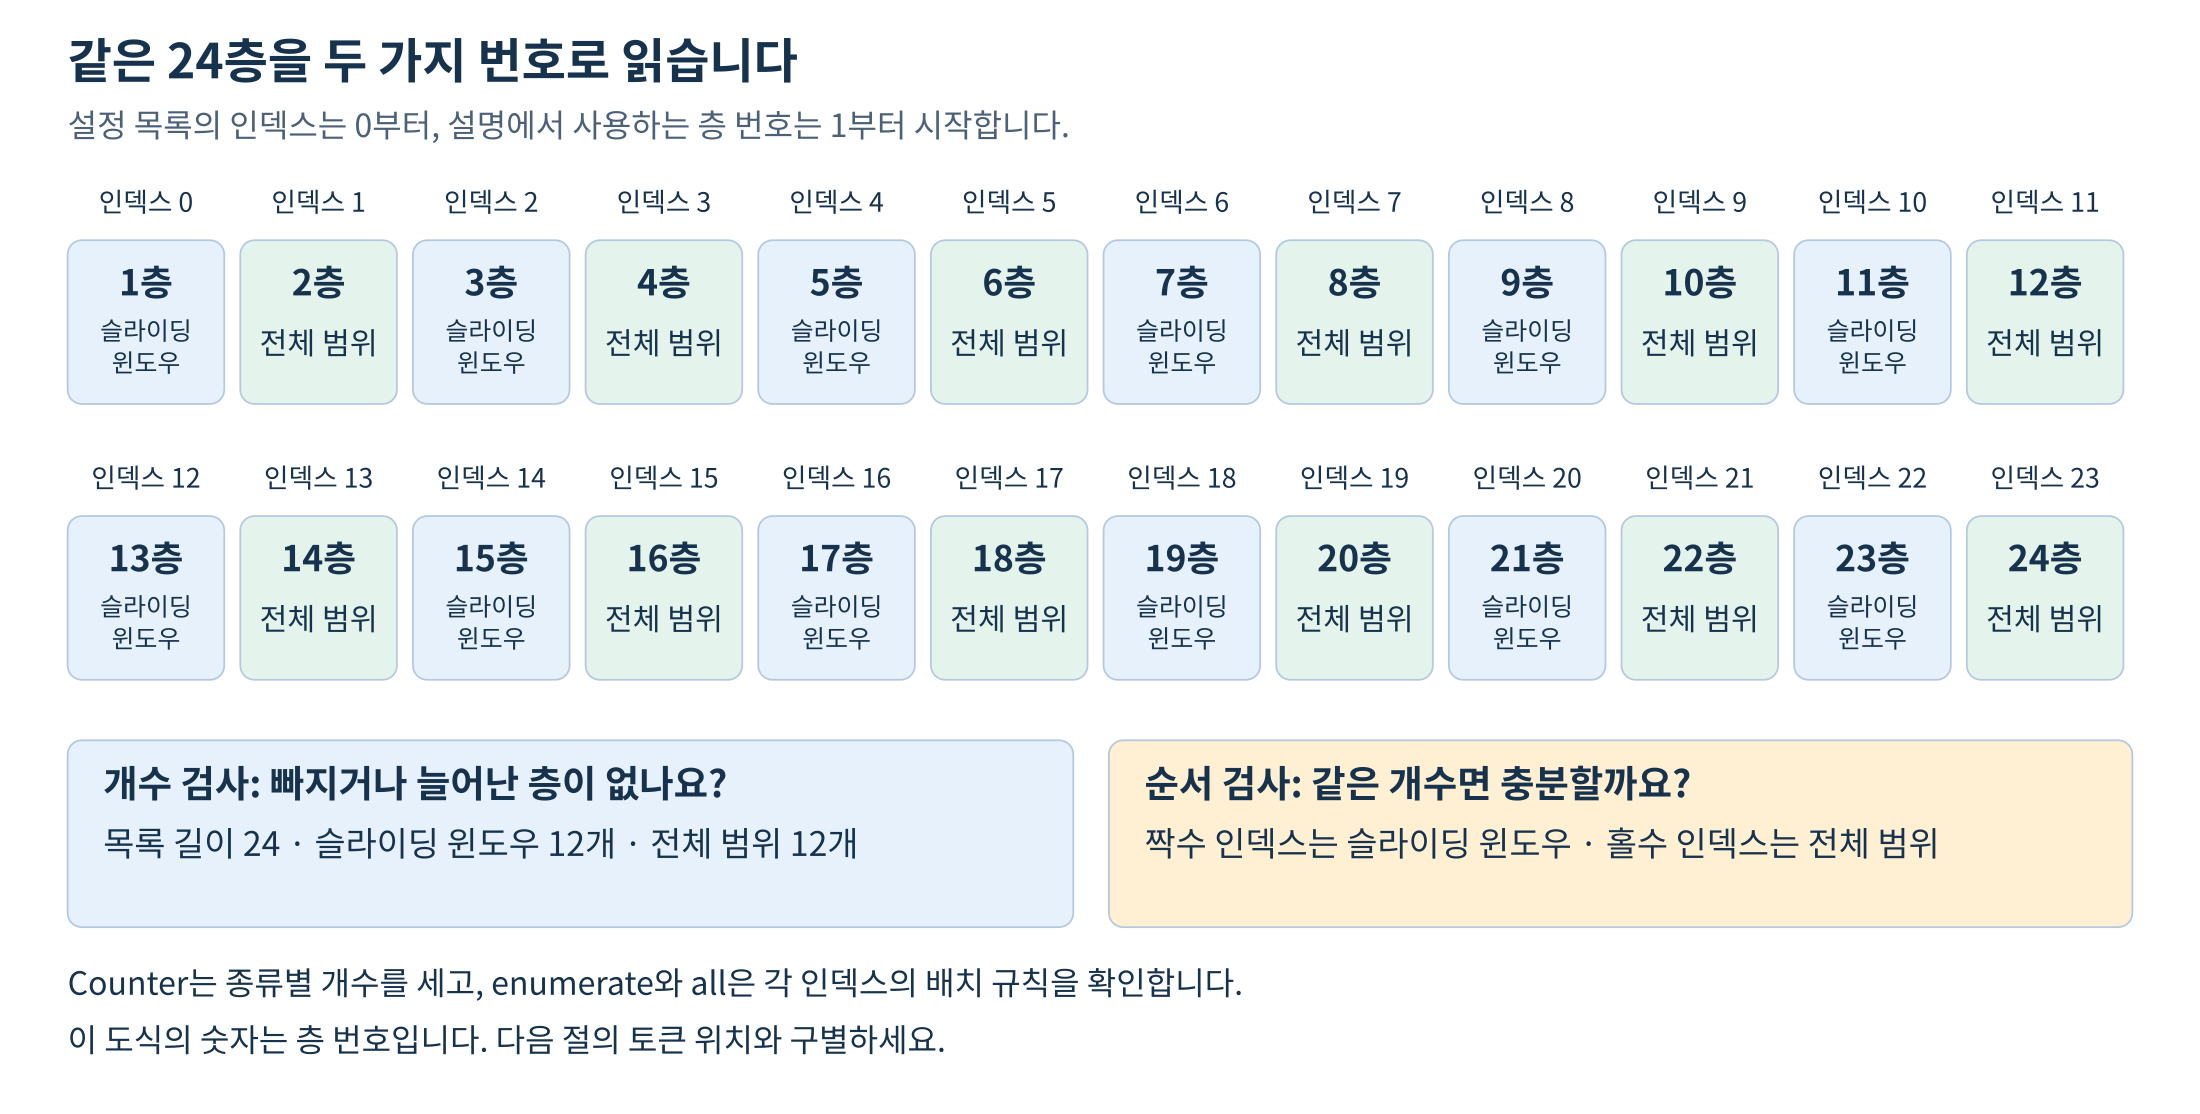

**그림 설명:** 인덱스에 1을 더하면 층 번호입니다. 개수 검사와 순서 검사는 서로 다른 조건을 확인합니다.


### 코드 설명: 목록 길이 → 종류별 개수 → 층별 순서

앞에서 복원한 공식 설정의 `layer_types`를 읽습니다. 먼저 목록 길이가 설정의 24층과 같은지 검사하고, `Counter`로 두 종류가 각각 12개인지 셉니다. 이어 `enumerate`로 각 항목의 인덱스를 얻고 `all`로 교대 규칙을 모든 층에서 확인합니다. 출력의 `index`와 `layer`를 한 쌍으로 읽으며, 첫 줄과 마지막 줄이 각각 어느 종류인지 확인하세요. 이 코드는 모델을 순전파하는 것이 아니라 설정에 적힌 순서를 검증합니다.


In [2]:
# types는 층 순서대로 나열된 문자열 목록입니다. 24개 항목은 24개 토큰이 아니라 24개 어텐션 층입니다.
types = config_data["layer_types"]
# 목록이 누락되거나 층 수와 다르면 뒤의 순서 비교가 의미 없으므로 먼저 길이를 확인합니다.
assert len(types) == config.num_hidden_layers
# Counter는 종류별 횟수만 집계하므로 배치 순서는 다음 all 검사로 따로 확인합니다.
counts = Counter(types)
assert counts == {"sliding_attention": 12, "full_attention": 12}
# i % 2는 인덱스의 짝·홀을 구분하고 all은 모든 층이 교대 규칙을 지키는지 검사합니다.
assert all(t == ("sliding_attention" if i % 2 == 0 else "full_attention") for i, t in enumerate(types))
# 인덱스는 0부터, 교육용 층 번호는 1부터 표시합니다.
for i, kind in enumerate(types):
    print(f"index {i:2d} / layer {i+1:2d}: {kind}")
# dict는 집계 결과를 일반 사전 형태로 표시하며 층을 실제 실행하는 과정이 아닙니다.
print("Counts:", dict(counts))
print("[PASS] 실제 24층 순서와 12:12 구성")

index  0 / layer  1: sliding_attention
index  1 / layer  2: full_attention
index  2 / layer  3: sliding_attention
index  3 / layer  4: full_attention
index  4 / layer  5: sliding_attention
index  5 / layer  6: full_attention
index  6 / layer  7: sliding_attention
index  7 / layer  8: full_attention
index  8 / layer  9: sliding_attention
index  9 / layer 10: full_attention
index 10 / layer 11: sliding_attention
index 11 / layer 12: full_attention
index 12 / layer 13: sliding_attention
index 13 / layer 14: full_attention
index 14 / layer 15: sliding_attention
index 15 / layer 16: full_attention
index 16 / layer 17: sliding_attention
index 17 / layer 18: full_attention
index 18 / layer 19: sliding_attention
index 19 / layer 20: full_attention
index 20 / layer 21: sliding_attention
index 21 / layer 22: full_attention
index 22 / layer 23: sliding_attention
index 23 / layer 24: full_attention
Counts: {'sliding_attention': 12, 'full_attention': 12}
[PASS] 실제 24층 순서와 12:12 구성


### 출력 설명: 24개 줄에서 개수와 배치 순서를 함께 봅니다

첫 줄의 `index 0 / layer 1`은 **하나의 같은 블록**을 두 번호 체계로 표시한 것입니다. 마지막 `index 23 / layer 24`까지 나오므로 총 24개입니다. 첫 층은 슬라이딩 윈도우, 둘째는 전체 범위이며 이 순서가 마지막 층까지 교대로 이어집니다.

`Counts`의 `sliding_attention: 12`, `full_attention: 12`는 각각의 개수입니다. 두 개수가 같다는 사실만으로 교대 배치가 보장되지는 않지만, 앞의 층별 목록과 통과한 순서 검사를 함께 보면 **슬라이딩 윈도우 → 전체 범위를 12번 반복한 구성**임을 알 수 있습니다.

‘전체 범위’ 층도 인과적 제약 안에서 현재와 과거를 읽습니다. 이 출력은 설정의 층 이름을 나열한 것이므로 24개 층을 실제 입력으로 실행했거나 먼 문맥을 정확히 기억함을 입증한 것은 아닙니다.

## 3. 실제 윈도우 크기로 읽을 수 있는 위치 계산하기

**이제 층 번호가 아니라 토큰 위치를 봅니다.** 현재 위치란 지금 표현을 계산하는 토큰의 순서입니다. 위치도 0부터 세므로 위치 127은 128번째 토큰입니다. 여기의 위치 숫자는 어휘를 구별하는 토큰 ID가 아닙니다.

**윈도우 크기 128에는 현재 위치도 포함됩니다.** 위치 127에서는 문장 시작인 0부터 현재인 127까지 정확히 128개가 있습니다. 따라서 슬라이딩 윈도우 어텐션과 전체 범위 어텐션 모두 같은 범위를 직접 참고할 수 있습니다. 다음 위치 128로 한 칸 이동하면 차이가 드러납니다. 전체 범위 어텐션은 시작 위치 0을 유지하여 0~128의 129개를 참고하지만, 슬라이딩 윈도우 어텐션은 시작점을 1로 옮겨 1~128의 128개만 참고합니다. 어느 경우에도 미래 위치는 포함하지 않습니다.

**개수는 양 끝을 포함해서 셉니다.** 위치 1부터 128까지의 개수는 `128−1+1=128`입니다. 그래서 시작점은 `현재 위치−윈도우 크기+1`로 계산하며, 문장 앞부분에서 음수가 나오면 0으로 제한합니다. 문장 길이가 아직 윈도우보다 짧다면 없는 과거 위치를 채워 넣지 않습니다.

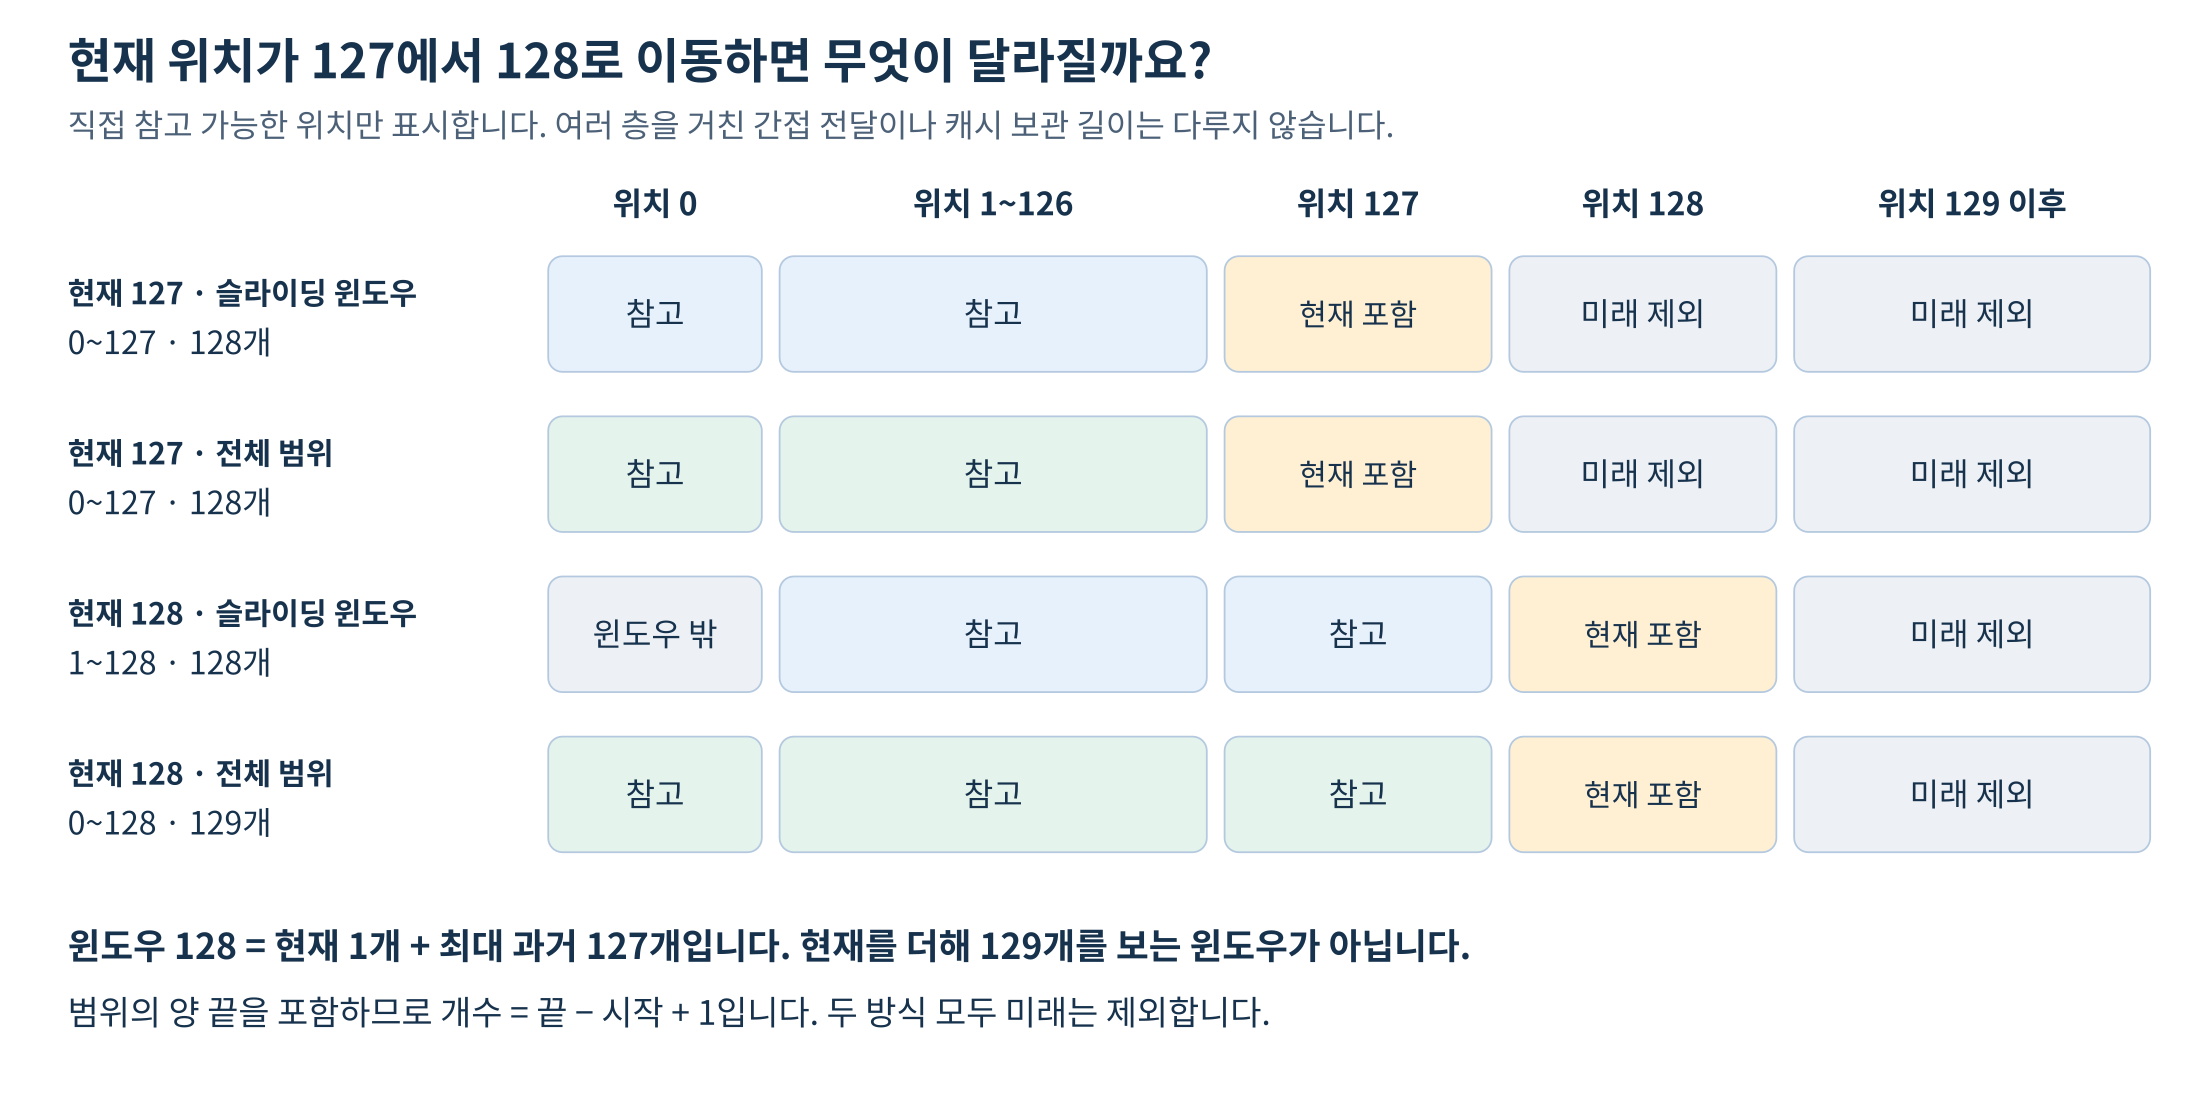

**그림 설명:** 윈도우가 처음 이동할 때 위치 0이 제외되는지 살펴보세요. 현재를 포함하며 미래는 두 방식 모두 제외합니다.


### 코드 설명: 경계 위치를 선택해 직접 참고 범위 확인하기

설정의 `sliding_window=128`을 가져와 `visible_range(position, kind)`에 현재 위치와 어텐션 종류를 전달합니다. 반환값은 `(시작 위치, 끝 위치, 위치 개수)`입니다. 위치 0에서는 시작 경계를, 127에서는 윈도우가 막 찬 시점을, 128에서는 윈도우가 처음 이동하는 시점을, 1023에서는 긴 문맥에서도 슬라이딩 윈도우 범위가 제한되는지 확인합니다.

아래 검사는 위치 128에서 슬라이딩 윈도우 `(1, 128, 128)`과 전체 범위 `(0, 128, 129)`를 구별합니다. 실제 어텐션 점수·학습 가중치·생성 문장을 계산하는 것은 아닙니다. 또한 ‘한 층에서 직접 참고할 수 있는 위치’를 계산하므로, 여러 층을 통한 간접 정보 전달이나 다음 호출을 위해 남기는 KV 캐시 길이와 혼동하지 마세요.


In [3]:
window = config.sliding_window
# position은 0부터 세는 위치, kind는 두 어텐션 종류 중 하나입니다.
# 반환은 위치 범위의 정수 세 개입니다. kind는 아래 호출처럼 두 종류만 사용하며 그 외 문자열을 별도 검증하지 않습니다.
def visible_range(position, kind):
    assert position >= 0
    # 현재 위치를 포함하는 범위이므로 시작점 계산에 +1이 필요합니다.
    # max(0, ...)는 문장 앞에서 시작 위치가 음수가 되는 것을 막습니다. else는 전체 인과 범위의 시작 0입니다.
    start = max(0, position - window + 1) if kind == "sliding_attention" else 0
    # 반환 튜플은 (시작, 끝, 개수)이며 양 끝을 포함해 개수에도 +1을 적용합니다.
    return start, position, position - start + 1
# 시작·윈도우를 채운 지점·윈도우가 처음 이동한 지점·긴 문맥을 차례로 비교합니다.
for position in (0, 127, 128, 1023):
    print("position", position, "sliding", visible_range(position, "sliding_attention"),
          "full", visible_range(position, "full_attention"))
# 윈도우 경계 직후의 반환값 자체를 검사합니다. 실제 어텐션 가중치 검사는 아닙니다.
assert visible_range(128, "sliding_attention") == (1, 128, 128)
assert visible_range(128, "full_attention") == (0, 128, 129)
print("[PASS] 실제 창 크기와 인과 범위의 경계 확인")

position 0 sliding (0, 0, 1) full (0, 0, 1)
position 127 sliding (0, 127, 128) full (0, 127, 128)
position 128 sliding (1, 128, 128) full (0, 128, 129)
position 1023 sliding (896, 1023, 128) full (0, 1023, 1024)
[PASS] 실제 창 크기와 인과 범위의 경계 확인


### 출력 설명: 윈도우가 처음 이동하는 순간을 찾습니다

각 괄호는 텐서 shape가 아니라 **(시작 위치, 끝 위치, 위치 개수)**입니다. 위치 번호는 0부터 셉니다.

- 위치 **0**에서는 두 방식 모두 `(0, 0, 1)`입니다. 읽을 과거가 없으므로 현재 위치 하나만 포함합니다.
- 위치 **127**에서도 두 방식 모두 `(0, 127, 128)`입니다. 문장 처음부터 현재까지가 정확히 윈도우 크기와 같기 때문입니다.
- 위치 **128**에서 처음 차이가 납니다. 슬라이딩 윈도우 어텐션은 `(1, 128, 128)`로 맨 앞 위치 0을 제외하고, 전체 범위는 `(0, 128, 129)`로 그대로 포함합니다. 윈도우 128은 ‘과거 128개에 현재를 더한다’는 뜻이 아닙니다.
- 위치 **1023**에서는 슬라이딩 윈도우 어텐션이 896~1023의 **128개**, 전체 범위가 0~1023의 **1024개**를 포함합니다. 입력이 길어져도 한 슬라이딩 윈도우 층의 직접 참고 범위는 늘지 않습니다.

PASS는 실제 설정의 윈도우 크기를 사용한 경계 산술이 맞았음을 뜻합니다. 실제 Q·K 점수를 계산한 결과가 아니며, 여러 층을 거친 간접 정보 전달까지 이 범위 함수 하나로 측정한 것도 아닙니다.

## 4. 실제 캐시 객체를 만들되 텐서는 채우지 않기

3절에서는 **현재 위치가 어디까지 읽을 수 있는지**를 계산했습니다. 이제는 그 계산이 끝난 뒤 **다음 호출을 위해 무엇을 남겨 두는지**를 살펴봅니다. 읽기 범위와 보관량은 서로 다른 시점의 수치이므로, 둘을 모두 ‘캐시 길이’라고 부르면 128과 127이 모순처럼 보일 수 있습니다.

### KV 캐시는 계산을 되풀이하지 않기 위한 저장소입니다

5교시에서 보았듯이, 다음 토큰을 처리할 때 과거 토큰의 K·V를 다시 계산하지 않고 가져올 수 있습니다. 다만 **모든 층이 같은 길이의 과거를 보관해야 하는 것은 아닙니다.** 전체 범위 층에는 오래된 위치도 직접 읽을 가능성이 있지만, 슬라이딩 윈도우 층에는 최근 윈도우를 넘어선 위치를 직접 읽지 않는 규칙이 있습니다.

**캐시 관리 구조를 보관함에 비유해 보겠습니다.** `DynamicCache` 하나가 모델 전체의 보관함이라면, `cache.layers`의 24개 항목은 **층마다 따로 둔 서랍 24개**입니다. `cache.layers[0]`은 1층, `cache.layers[23]`은 24층에 대응합니다. 이 모델에서는 슬라이딩 윈도우용 서랍 12개와 전체 범위 어텐션용 서랍 12개가 준비됩니다. 서랍 하나가 토큰 하나를 뜻하는 것은 아닙니다. 각 서랍에는 그 층이 보관할 여러 토큰 위치의 K·V가 들어갈 수 있습니다.

같은 토큰 위치라도 층마다 처리한 표현이 다르므로, 각 층은 **자신이 계산한 별도의 K·V**를 보관합니다. 한 층의 K·V를 모든 층이 함께 쓰는 구조가 아닙니다. 이번 실습에서는 이 관리 객체와 층별 서랍만 만들고, 실제 K·V 텐서는 채우지 않습니다. 따라서 서랍의 종류와 빈 상태를 확인하는 것이지 모델의 캐시 값을 관찰하는 것은 아닙니다.

새 토큰 하나를 처리할 때, 슬라이딩 윈도우 층은 캐시에 남겨 둔 직전 최대 127개 위치의 K·V를 **현재 토큰의 K·V와 함께** 읽습니다. 그래서 한 번에 읽는 범위는 최대 128개 위치입니다. 전체 범위 층은 캐시에 저장된 이전 위치의 K·V를 모두 읽고, 현재 토큰의 K·V도 함께 사용합니다.

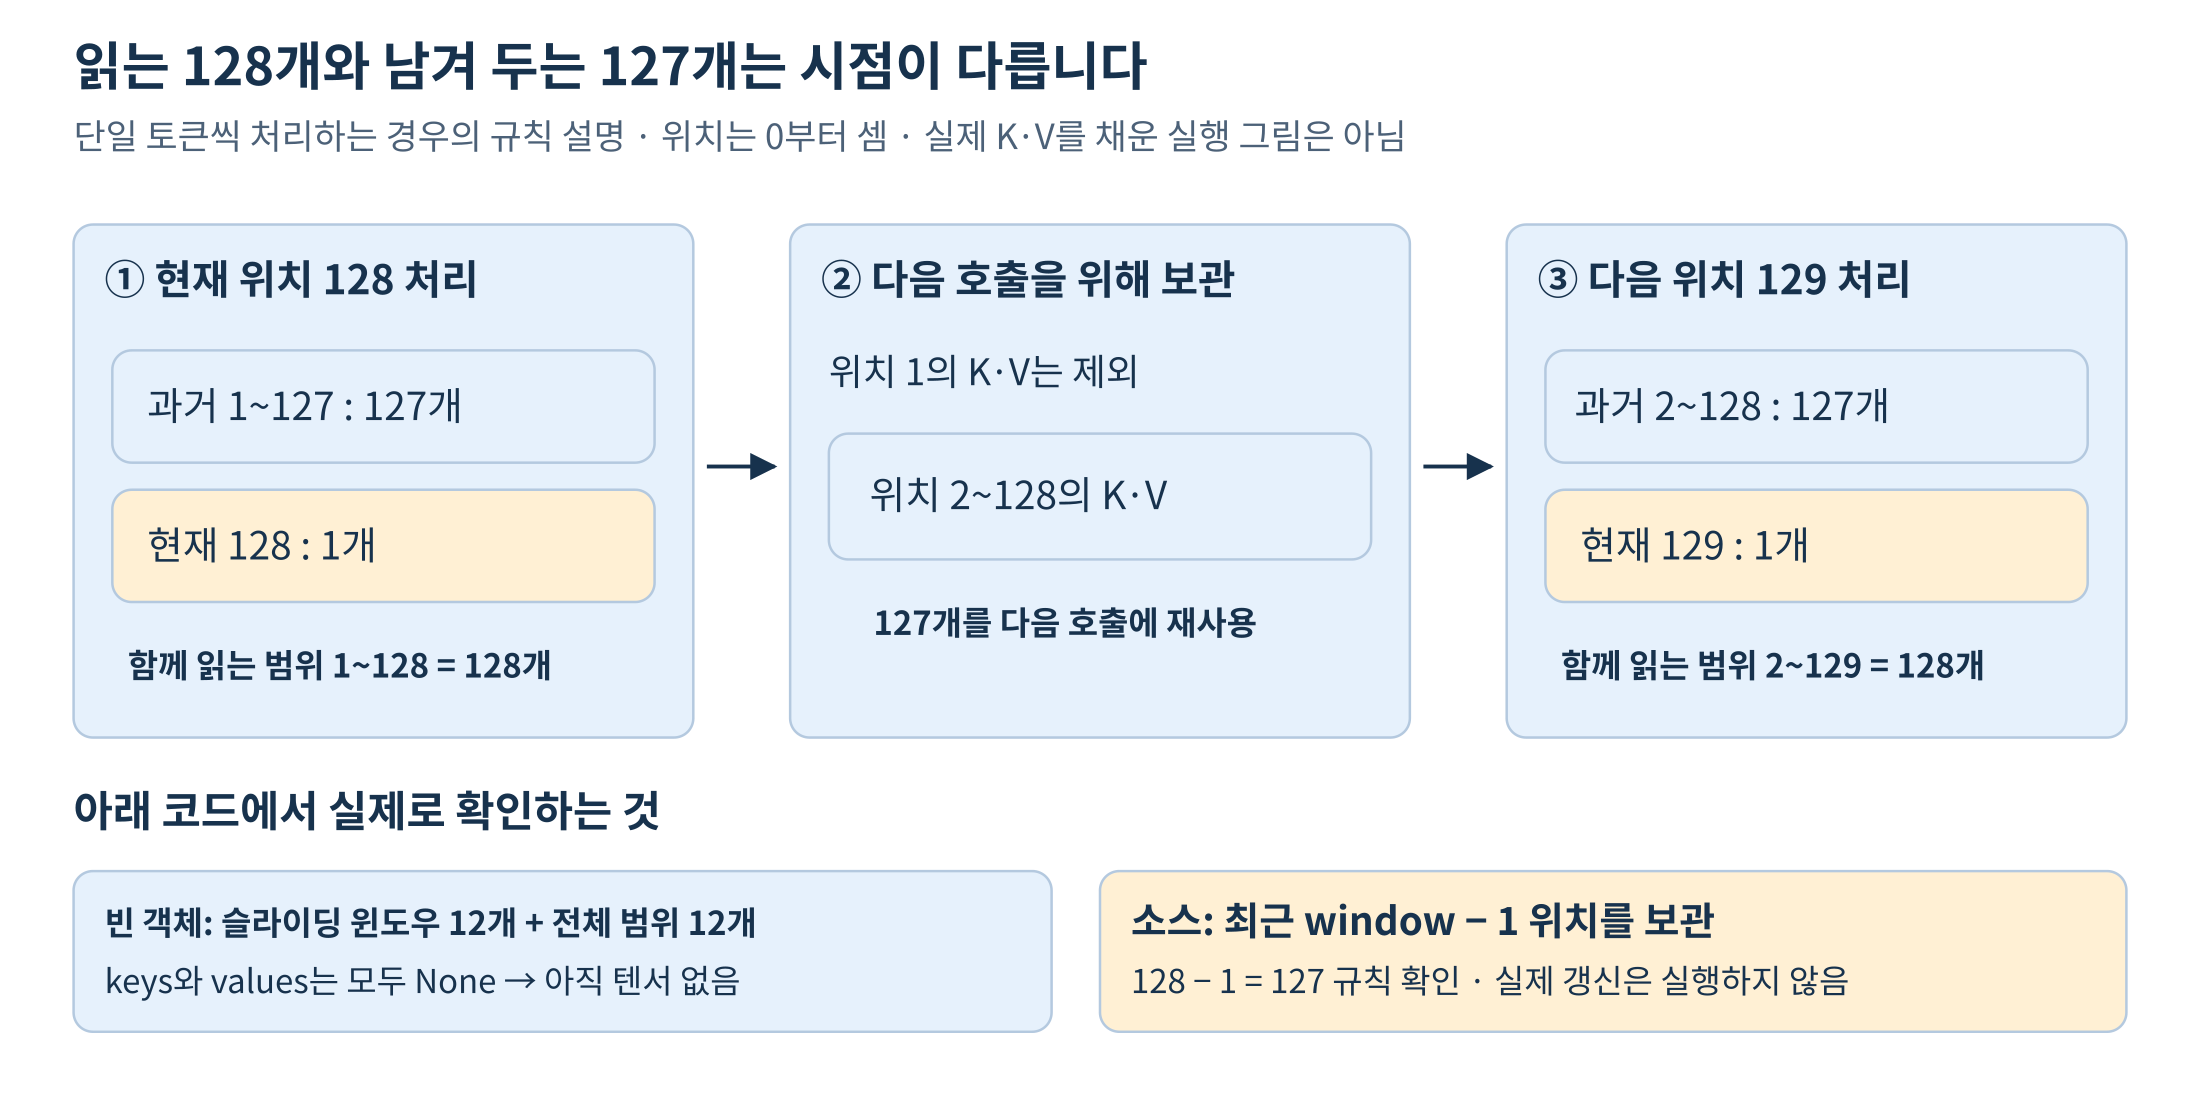

**이번에 읽은 범위와 다음 단계에 남길 범위를 구별하세요.** 현재 위치 128에서 읽는 범위는 `1~128`입니다. 다음 위치 129의 윈도우는 `2~129`가 되므로, 위치 1은 더 이상 필요하지 않고 `2~128`의 과거 K·V 127개를 남깁니다. 다음 호출에서 새 현재 위치 129의 K·V를 함께 사용하면 다시 128개 위치를 읽습니다. 문장 시작처럼 과거가 적으면 보관 개수도 127개보다 적습니다.

**그림 설명:** 위쪽은 설치된 보관 규칙을 단일 토큰 처리에 적용한 설명입니다. 아래쪽은 실제 코드의 확인 범위입니다. 이번 셀은 빈 객체와 소스만 확인하며 그림의 K·V를 실제로 채우거나 갱신하지 않습니다.


### 코드 설명: 빈 객체 확인과 함수 소스 추출

이번 코드는 두 가지 증거를 구별해서 확인합니다.

1. **어떤 저장 관리 객체가 준비되는가?** `DynamicCache(config=config)`로 모델이 아닌 캐시 관리 객체를 만듭니다. `cache.layers`의 각 항목을 설정의 층 종류와 짝지어 검사합니다. 저장 출력의 `DynamicSlidingWindowLayer: 12`, `DynamicLayer: 12`는 두 종류가 각각 12개라는 뜻입니다. `keys is None`과 `values is None` 검사도 통과하지만 값 자체를 출력하지는 않습니다. `None`은 K·V 텐서가 없다는 뜻이며, 0으로 채운 텐서나 길이 0인 텐서와도 다릅니다.
2. **나중에 갱신하면 무엇을 남기는가?** 설치된 `cache_utils.py`를 문자열로 읽고, AST(파이썬 문법 구조를 나타내는 트리)에서 슬라이딩 윈도우 클래스의 `update` 함수를 찾습니다. `ast.get_source_segment`는 그 함수의 원문을 꺼내며 함수를 실행하지 않습니다. 원문의 `-self.sliding_window + 1` 슬라이스는 윈도우 128에서 최근 127개 위치를 남기는 규칙의 단서입니다.

출력에 나오는 여러 `self.keys = ...`, `self.values = ...`는 **서로 다른 분기의 소스 줄**도 포함합니다. 위에서 아래로 모두 실행된 기록으로 읽지 마세요. PASS는 빈 객체의 종류·빈 상태와 보관 규칙의 소스 확인을 뜻하며, 실제 캐시 갱신이나 메모리 사용량 측정의 성공을 뜻하지 않습니다. 이 규칙을 다음 절의 저장량 계산에 사용합니다.


In [4]:
# 설정별 빈 캐시만 만들며 아직 K·V 텐서는 저장하지 않습니다.
cache = DynamicCache(config=config)
assert len(cache.layers) == 24
# type(...).__name__은 객체의 클래스 이름 문자열입니다. 실제 캐시 값·길이를 출력하는 것이 아닙니다.
cache_types = [type(layer).__name__ for layer in cache.layers]
# 설정 종류와 빈 캐시를 같은 층끼리 짝지어 클래스 이름을 비교합니다.
for kind, layer in zip(types, cache.layers):
    expected = "DynamicSlidingWindowLayer" if kind == "sliding_attention" else "DynamicLayer"
    assert type(layer).__name__ == expected
    # None은 텐서가 아직 없다는 뜻이며 길이 0 텐서와도 다릅니다.
    assert layer.keys is None and layer.values is None
print("Cache types:", dict(Counter(cache_types)))
# 현재 설치된 패키지 경로에서 소스를 읽습니다. 파일을 실행하지 않습니다.
source_path = Path(transformers.__file__).parent / "cache_utils.py"
source = source_path.read_text(encoding="utf-8")
# AST는 문법 구조입니다. next로 해당 클래스와 update 함수의 정의 노드를 찾습니다.
tree = ast.parse(source)
sliding_class = next(n for n in tree.body if isinstance(n, ast.ClassDef) and n.name == "DynamicSlidingWindowLayer")
update = next(n for n in sliding_class.body if isinstance(n, ast.FunctionDef) and n.name == "update")
# 함수 노드에 해당하는 원문 문자열을 추출해 보관 슬라이스를 확인합니다.
# source와 AST 노드는 동일 파일에서 얻어야 합니다. 문자 포함 검사는 구현 단서를 찾을 뿐 모든 분기의 동작 증명은 아닙니다.
update_source = ast.get_source_segment(source, update)
assert "-self.sliding_window + 1" in update_source
print("Installed cache source SHA256:", hashlib.sha256(source.encode()).hexdigest())
# 서로 다른 분기의 대입문도 함께 출력됩니다. 연속 실행 순서로 읽지 않습니다.
for line in update_source.splitlines():
    if "self.keys =" in line or "self.values =" in line:
        print(line.strip())
print("[PASS] 실제 빈 캐시 클래스와 보관 규칙 소스 확인")

Cache types: {'DynamicSlidingWindowLayer': 12, 'DynamicLayer': 12}
Installed cache source SHA256: bf5e6269ba573a541462f41f0388a50ec114299dc736f97c344cc6e3345a8fa3
self.keys = full_key_states[:, :, -self.sliding_window + 1 :, :]
self.values = full_value_states[:, :, -self.sliding_window + 1 :, :]
self.keys = full_key_states
self.values = full_value_states
[PASS] 실제 빈 캐시 클래스와 보관 규칙 소스 확인


### 출력 설명: 객체 종류와 소스 문장을 구분합니다

`DynamicSlidingWindowLayer` 12개와 `DynamicLayer` 12개가 만들어졌습니다. 앞에서 읽은 슬라이딩 윈도우 12층·전체 범위 12층과 **캐시 관리 객체의 종류가 대응**합니다. 빈 상태 검사도 통과했으므로 이 시점에 모델이 계산한 K·V 텐서는 들어 있지 않습니다.

이어서 보이는 `self.keys = ...`, `self.values = ...`는 텐서 내용이 아니라 **설치된 update 함수에서 추출한 코드 줄**입니다. 슬라이스의 축은 `(배치, KV 헤드, 위치, 헤드 차원)` 순서이며, 세 번째 축의 `-self.sliding_window + 1`은 윈도우 128에서 최근 127개 위치를 남기는 규칙입니다. 다음 현재 토큰까지 포함해 읽는 윈도우 128과, 호출 이후 남겨 둘 과거 127을 구분하세요.

아래의 전체 대입문들은 같은 함수의 다른 분기에서 추출된 줄이므로 위 슬라이스 다음에 무조건 다시 전체를 저장한다는 실행 순서로 읽지 않습니다. 소스 SHA256은 이 규칙을 읽은 설치 파일의 식별 정보입니다. PASS는 빈 객체와 구현 규칙 확인이며 실제 캐시 갱신이나 메모리 측정 성공은 아닙니다.

## 5. 길이가 늘 때 저장량을 공식으로 비교하기

4절에서 ‘무엇을 남기는가’를 확인했으므로, 이번에는 그 K·V에 몇 바이트가 필요한지 계산합니다. **배치 1, FP32**를 분석 조건으로 정합니다. 실제 모델 가중치의 양자화 형식과 캐시에 가정한 자료형은 별개입니다. 텐서를 만들거나 GPU 메모리를 측정하지 않습니다.

### 저장량 공식과 실제 메모리 측정 구분하기

먼저 **보관 칸 하나는 한 층의 토큰 위치 하나에 해당하는 K·V 한 쌍**이라고 정하겠습니다. 앞 절의 층별 서랍에는 이러한 칸이 여러 개 들어갈 수 있습니다. 이 ‘칸’은 저장량을 세기 위한 개념적 단위이며, 실제 메모리에 작은 객체를 칸마다 따로 만든다는 뜻은 아닙니다.

한 칸의 **K는 KV 헤드 8개 × 헤드당 성분 64개 = 512개 성분**입니다. **V도 같은 구성으로 512개 성분**입니다. K와 V를 합하면 `512 + 512 = 1,024`개의 FP32 원소이며, 원소 하나가 4바이트이므로 `(8 × 64 + 8 × 64) × 4 = 4,096바이트`입니다. 코드의 `2 × 8 × 64 × 4`도 같은 계산입니다. Query 헤드 수는 곱하지 않습니다. 보관 대상은 Q가 아니라 K·V이기 때문입니다.

다음으로 각 층이 보관하는 위치 수를 셉니다. 여기서 **`N`은 모델이 지금까지 실제로 처리한 누적 토큰 수**입니다. 처음 처리한 프롬프트 토큰과 그 뒤 모델에 입력하여 처리를 마친 토큰을 합합니다. 이번 호출에 새로 넣은 토큰 수만을 뜻하지 않으며, 다음 토큰으로 선택했지만 아직 모델에 다시 입력해 처리하지 않은 토큰은 포함하지 않습니다.

예를 들어 먼저 프롬프트 1,023개 토큰을 처리하고, 다음 호출에서 새 토큰 1개를 처리했다면 그 호출의 입력은 1개지만, 지금까지 처리한 누적 토큰은 1,024개입니다. 따라서 `N=1,024`입니다. 위치를 0부터 세면 0~1023을 처리한 상태입니다. 이 예시는 누적량의 뜻을 설명하기 위한 것이며 이번 셀에서 실제 프롬프트나 모델을 실행하지는 않습니다.

**호출 이후 보관량**은 전체 범위 어텐션 12층에서 각각 `N`개, 슬라이딩 윈도우 12층에서 각각 `min(N, 127)`개로 계산합니다. 슬라이딩 윈도우의 127은 다음 호출용으로 남기는 과거 K·V의 최대 개수입니다. 다음 현재 토큰의 K·V까지 함께 읽는 **최대 읽기 범위 128**과는 다릅니다. 

**한 층의 K와 V 텐서를 따로 보면**, 각각의 형상은 `(1, 8, T, 64)`로 생각할 수 있습니다. 축은 차례로 배치 1개, KV 헤드 8개, **그 층에 남긴 위치 수 `T`**, 헤드당 성분 64개입니다. K와 V는 이 형상의 별도 텐서 두 개이지, K와 V를 합친 텐서 하나가 아닙니다.

`N`은 지금까지 처리한 누적 토큰 수이고, `T`는 그중 **해당 층이 호출 후 보관하는 위치 수**입니다. `N=1,024`라면 전체 범위 층은 `T=1,024`, 슬라이딩 윈도우 층은 `T=127`입니다. 이 형상은 설정과 보관 규칙을 이해하기 위한 설명이며, 이번 실습에서 실제로 만든 텐서나 측정한 메모리가 아닙니다.

`N=1,024`인 상태의 보관량을 계산하면 다음과 같습니다.

- 전체 범위 층: `12 × 1,024 = 12,288`개의 **층별 보관 칸**
- 슬라이딩 윈도우 층: `12 × 127 = 1,524`개의 **층별 보관 칸**
- 합계: `(12,288 + 1,524) × 4,096 = 56,573,952바이트`

**같은 토큰도 층마다 따로 보관한다는 점을 생각해 보세요.** 지금까지 처리한 토큰은 1,024개이며, 마지막 토큰의 위치는 1,023입니다. 이 위치의 토큰 하나도 전체 범위 어텐션 12층과 슬라이딩 윈도우 어텐션 12층에 각각 보관됩니다. 각 층이 계산한 별도의 K·V 한 쌍이 필요하므로, 마지막 토큰 하나에 대해서만 세어도 24개의 보관 칸을 쓰는 셈입니다. 층마다 계산한 값이므로 같은 수치의 복사본을 24개 둔다는 뜻은 아닙니다.

이처럼 **한 층의 한 위치에 해당하는 K·V 한 쌍을 담는 칸**을 24층 전체에서 더한 값이 `12,288 + 1,524 = 13,812`입니다. 오래된 위치는 전체 범위 층에만 남고 최근 127개 위치는 슬라이딩 윈도우 층에도 남으므로, 모든 토큰이 항상 24칸씩 남는 것은 아닙니다. 처리한 문장의 토큰 수는 여전히 **1,024개**이고, 층별 보관 칸의 합이 **13,812개**입니다. 이 칸 하나의 크기 4,096바이트를 곱해 위 저장량을 구합니다.

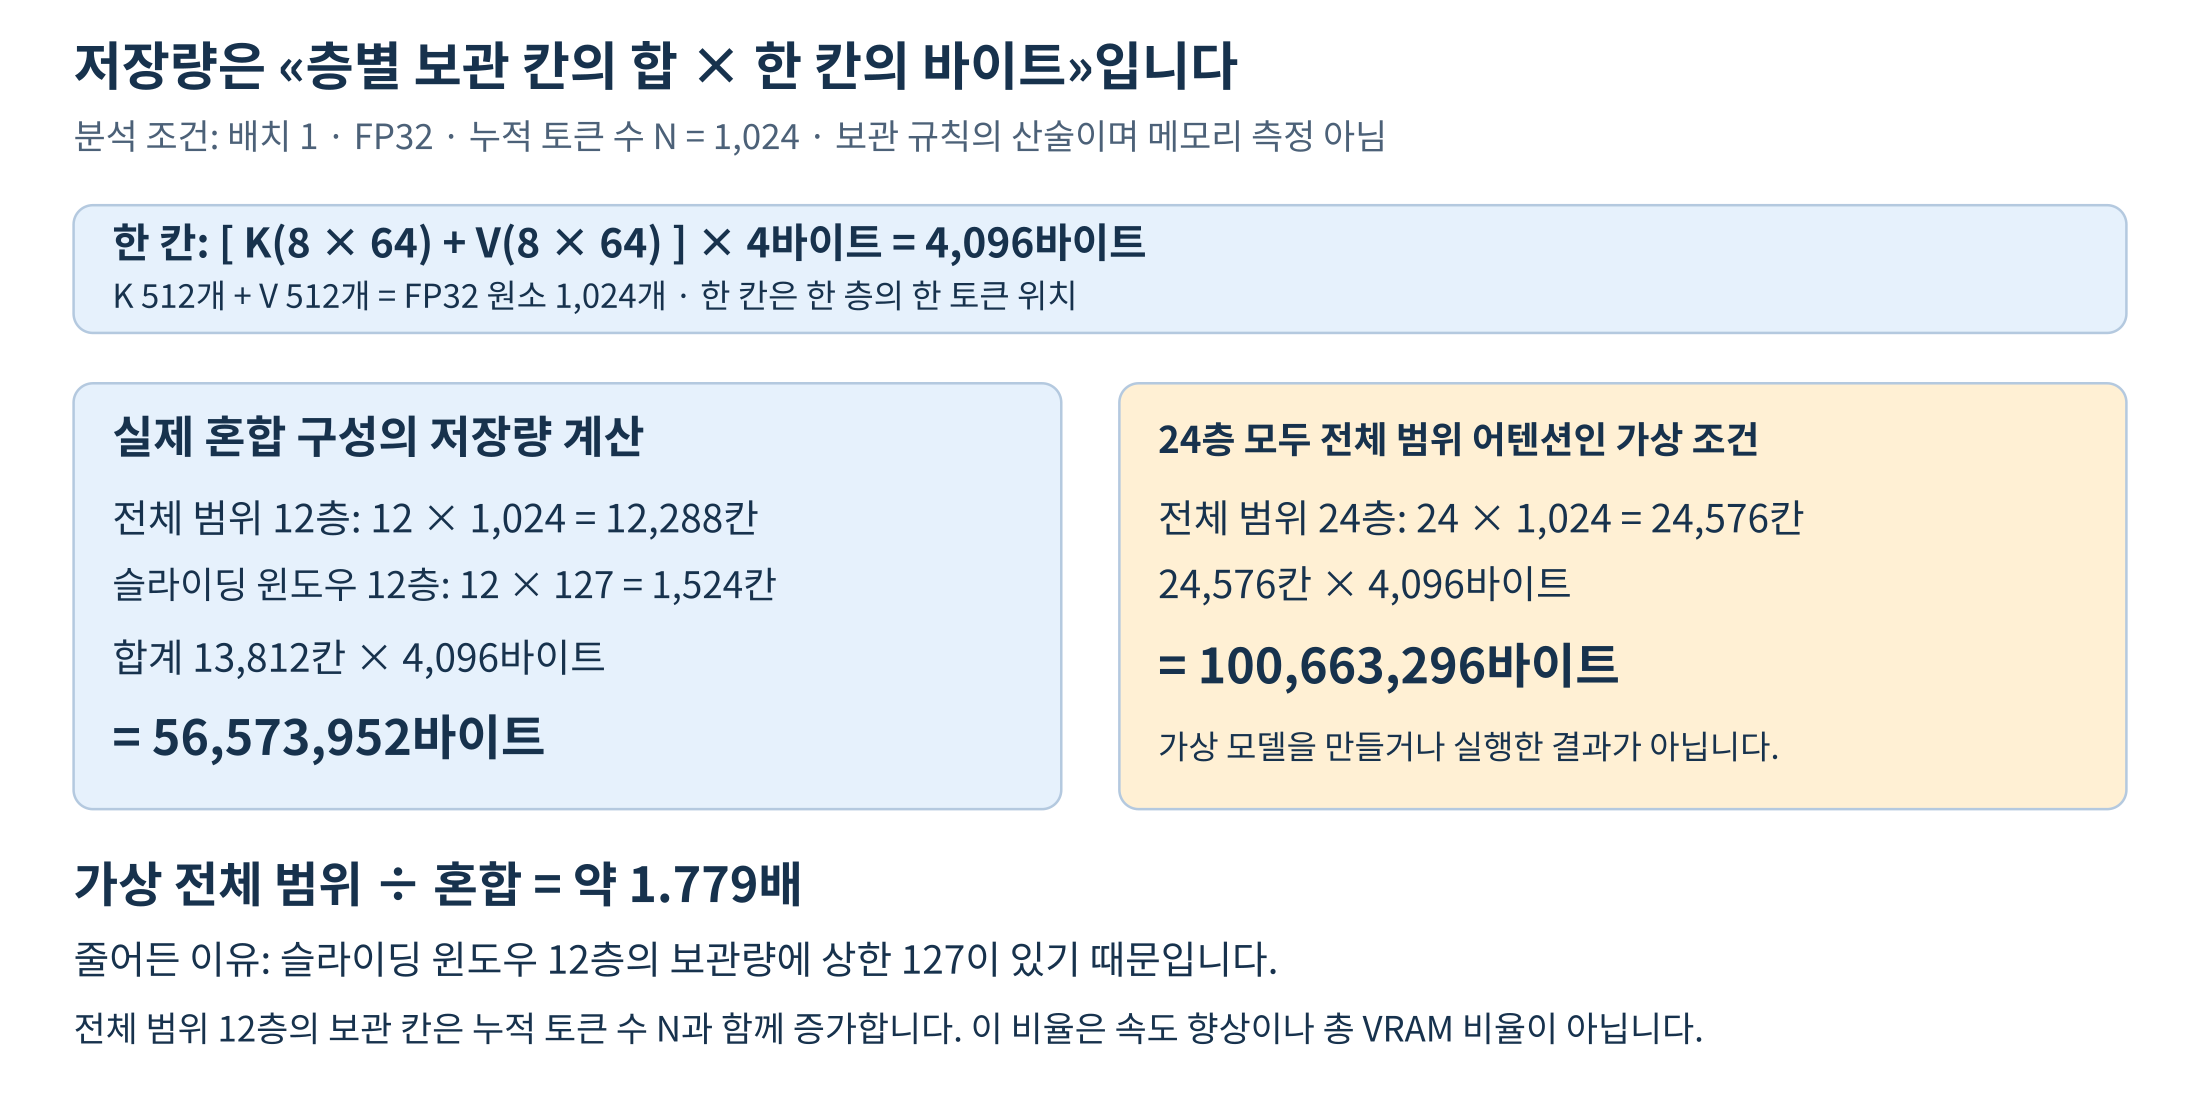

**그림 설명:** 양쪽 모두 같은 위치당 바이트 수를 사용하고 보관 위치 수만 달리 계산합니다. 그림의 숫자는 두 노트북에 저장된 산술 출력과 일치합니다. 오른쪽은 가상 비교 조건이며 별도 모델 실행이나 메모리 벤치마크가 아닙니다.


### 코드 설명: 반복문의 계산 단위 추적하기

`bytes_per_layer_position`은 한 층·한 위치의 K+V 바이트 수입니다. `length`는 위에서 정의한 누적 토큰 수 `N`입니다. 반복문은 누적 128, 1,024, 8,192토큰에 대해 `retained_positions`로 모든 층의 보관 위치 수를 더하고, 여기에 4,096을 곱해 `mixed_bytes`를 구합니다. 비교값 `hypothetical_full_bytes`는 **나머지 조건을 그대로 두고 24층 모두 전체 범위 어텐션이라고 가정**한 계산입니다. 가상 모델을 새로 만들거나 실행하지 않습니다.

저장 출력에서 `N=1,024`의 혼합 값은 **56,573,952바이트**, 가상 전체 범위 값은 **100,663,296바이트**입니다. `ratio`는 **가상 전체 범위 ÷ 혼합**이므로 약 **1.779**입니다. ‘혼합이 1.779배 빠르다’는 뜻은 아닙니다. 길이 128에서는 약 1.004, 길이 8,192에서는 약 1.969로 변합니다. 슬라이딩 윈도우 쪽은 상한에 도달하지만 전체 범위 12층의 저장량은 계속 늘어나기 때문입니다. 따라서 혼합 모델 전체의 캐시가 상수 크기가 되지는 않습니다.

마지막 검사는 누적 1,024토큰 조건의 정수 산술을 다시 확인합니다. 두 PASS는 구현 규칙에 따른 저장량 계산과 이번 설정·소스 분석이 완료됐다는 뜻입니다. 가중치·임시 텐서·갱신 도중의 메모리를 포함한 총 VRAM이나 실제 생성 성능은 이번 계산의 범위가 아닙니다.


In [5]:
# 배치 1과 float32를 가정한 K·V 원소의 저장량이며 실제 메모리 측정이 아닙니다.
bytes_per_layer_position = 2 * config.num_key_value_heads * config.head_dim * 4
assert bytes_per_layer_position == 4096
for length in (128, 1024, 8192):
    # 전체 층은 N, 슬라이딩 층은 min(N,127)개를 보관한다는 규칙을 층별로 합칩니다.
    retained_positions = counts["full_attention"] * length + counts["sliding_attention"] * min(length, window - 1)
    # retained_positions는 층별 보관 위치 수의 합입니다. 토큰 수 하나와 다르며 위치당 바이트를 곱해야 전체 바이트가 됩니다.
    mixed_bytes = retained_positions * bytes_per_layer_position
    # 24층이 모두 전체 범위 어텐션이라고 가정한 산술 비교이며 별도 모델 실행이 아닙니다.
    hypothetical_full_bytes = config.num_hidden_layers * length * bytes_per_layer_position
    print("N", length, "mixed analytical bytes", mixed_bytes,
          "hypothetical all-full bytes", hypothetical_full_bytes,
          "ratio", hypothetical_full_bytes / mixed_bytes)
# 대표 길이 1024의 계산을 재확인합니다. 바이트 비율은 속도 향상 배수가 아닙니다.
assert (12 * 1024 + 12 * 127) * 4096 == 56573952
print("[PASS] 구현 규칙 기반 저장량 공식 계산 (실제 모델 추론 아님)")
print("[PASS] Lesson 06 분석 완료")

N 128 mixed analytical bytes 12533760 hypothetical all-full bytes 12582912 ratio 1.003921568627451
N 1024 mixed analytical bytes 56573952 hypothetical all-full bytes 100663296 ratio 1.779322328410078
N 8192 mixed analytical bytes 408895488 hypothetical all-full bytes 805306368 ratio 1.969467484072605
[PASS] 구현 규칙 기반 저장량 공식 계산 (실제 모델 추론 아님)
[PASS] Lesson 06 분석 완료


### 출력 설명: 길이가 길어질수록 두 저장량의 차이가 커집니다

출력의 `N`은 각 조건에서 처리했다고 가정한 **누적 토큰 수**이며, 한 번의 호출에 새로 넣는 입력 토큰 수가 아닙니다.

모든 값은 **배치 1·FP32·위치당 K+V 4096바이트**를 가정하고 실제로 실행한 산술 결과입니다. `mixed`는 전체 범위 12층과 슬라이딩 윈도우 12층, `hypothetical all-full`은 24층 모두 전체 범위 어텐션이라고 놓은 가상 비교 조건입니다.

- **N=128:** 혼합 12,533,760바이트와 가상 전체 범위 12,582,912바이트가 거의 같습니다. 아직 문장이 짧아 슬라이딩 윈도우의 보관 제한으로 줄어드는 양이 작습니다. 비율은 약 **1.004**입니다.
- **N=1024:** 혼합 56,573,952바이트, 가상 전체 범위 100,663,296바이트이며 비율은 약 **1.779**입니다. 슬라이딩 윈도우 층은 최대 127개 과거 위치만 남기지만 전체 범위 층의 저장량은 길이와 함께 늘어납니다.
- **N=8192:** 혼합 408,895,488바이트, 가상 전체 범위 805,306,368바이트이며 비율은 약 **1.969**입니다. 비율은 ‘가상 전체 범위 ÷ 혼합’이므로 이 조건의 KV 저장량 비교입니다.

혼합 구성에도 전체 범위 층이 남아 있어 **모델 전체 캐시가 상수 크기가 되지는 않습니다.** 두 PASS는 공식 계산과 교시 분석의 완료 표시입니다. 바이트 수는 실제 할당한 GPU 메모리나 가중치·임시 버퍼 포함 총량이 아니며 비율도 속도 향상 배수가 아닙니다.

## 정리와 자기 점검
전체 범위 층이 남아 있으므로 이 모델 전체 캐시가 입력 길이와 무관한 상수 크기가 되지는 않습니다. 윈도우 밖의 정보를 직접 읽지 않는 것과 모델 전체가 그 정보를 전혀 전달할 수 없다는 것은 다릅니다. gpt-oss의 attention sink는 추가 설계 요소이며 미래 토큰 접근이나 별도 과거 토큰 캐시라는 뜻이 아닙니다. 이번 분석에는 sink 관련 성능 주장을 포함하지 않습니다.


- [ ] 직접 읽는 윈도우 128과 다음 호출을 위해 남기는 과거 127은 왜 다른가요?

  **핵심 답:** 직접 읽는 윈도우는 현재 토큰까지 포함한 128위치이고, 확인한 구현이 다음 호출을 위해 남기는 과거는 최대 127위치입니다.

  **이유:** 다음 토큰을 처리할 때 그 현재 위치를 더하면 과거 127 + 현재 1 = 128이 됩니다. 따라서 접근 범위의 크기와 갱신 후 지속 보관량은 같은 항목이 아닙니다.

- [ ] 전체 범위 층이 남아 있을 때 모델 전체 캐시가 길이와 무관한 상수 크기가 되나요?

  **핵심 답:** 아닙니다. 전체 범위 어텐션 12층의 캐시가 처리 길이와 함께 늘어납니다.

  **이유:** 이번 산술은 전체 범위 층에 길이 N, 슬라이딩 윈도우 층에 min(N, 127)을 적용합니다. 슬라이딩 윈도우 부분에 상한이 있어도 두 부분을 합한 전체 저장량에는 N에 비례하는 항이 남습니다.


## 참고 자료

- OpenAI, [gpt-oss Model Card §2.2: Architecture](https://arxiv.org/html/2508.10925#S2.SS2): 전체 범위·슬라이딩 윈도우 어텐션 교대와 MoE 설계.
- Jiang 외, [Mistral 7B §2: Sliding Window Attention](https://arxiv.org/html/2310.06825#S2): 제한된 직접 참고 범위와 층을 통한 정보 전달. 이번 체크포인트를 Mistral이라고 부르지 않습니다.
- [공식 고정 config](https://huggingface.co/openai/gpt-oss-20b/blob/6cee5e81ee83917806bbde320786a8fb61efebee/config.json), [라이선스](https://huggingface.co/openai/gpt-oss-20b/blob/6cee5e81ee83917806bbde320786a8fb61efebee/LICENSE): Apache 2.0. 포함된 JSON은 출처의 원본 바이트입니다.
- [Transformers v5.23.0 DynamicCache](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/cache_utils.py#L1960), [GPT-OSS 구현](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/models/gpt_oss/modeling_gpt_oss.py). 설치 버전은 첫 셀에서 출력합니다.